# CROSSGATE Actor梯度诊断

## tl;dr

新版CROSSGATE的Actor参数梯度确实比旧版和MLP大，但证据不支持“梯度爆炸”。梯度全程有限、没有NaN/Inf、在中期达到峰值后持续下降，Critic与TD误差也保持稳定。更准确的判断是：**Actor存在偏高的结构性梯度尺度和后期过训练风险，但当前并未数值失稳**。

最需要处理的是Actor优化尺度和监控缺口，而不是修改Critic：增加分微网/分支梯度记录，使用温和的Actor梯度裁剪或学习率调度，并保留验证早停。

## Context & Methods

本诊断比较新版CROSSGATE、旧版CROSSGATE和ESS-sharing MLP的5000回合训练记录，并使用新版与MLP各自的`best_model.pt`，在相同55个确定性测试日上重新计算策略梯度。

### Key Assumptions

- 训练历史中的`actor_grad_norm`是三个Actor全参数梯度L2范数的平均值，不是单层最大梯度。
- 最优检查点梯度分解使用测试状态分布和检查点Critic，因此用于定位梯度来源，不等同于训练时Replay Buffer分布。
- 单随机种子只能支持当前运行的诊断，不能证明跨种子稳定性。

In [1]:
from pathlib import Path
import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "outputs").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from algorithms.registry import get_algorithm_spec
from envs.multi_microgrid_env import MultiMicrogridEnv

RUNS = {
    "新版CROSSGATE": ROOT / "outputs/crossgate_actor/runs/CROSSGATEACTOR_2026-09-03_19-40-35_seed42",
    "旧版CROSSGATE": ROOT / "outputs/crossgate_actor/runs/CROSSGATEACTOR_2026-09-03_17-56-03_seed42",
    "ESS-sharing MLP": ROOT / "outputs/matd3_ess_sharing/runs/MATD3ESSSPATIOTEMPORALSHARING_2026-09-03_16-46-49_seed42",
}
HISTORIES = {
    name: pd.DataFrame(json.loads((path / "training_history.json").read_text(encoding="utf-8")))
    for name, path in RUNS.items()
}
VALIDATION = {
    name: pd.DataFrame(json.loads((path / "validation_history.json").read_text(encoding="utf-8")))
    for name, path in RUNS.items()
}

## Data

### 1. Validate source completeness

In [2]:
quality_rows = []
for name, frame in HISTORIES.items():
    grad = pd.to_numeric(frame["actor_grad_norm"], errors="coerce")
    quality_rows.append({
        "method": name,
        "episodes": len(frame),
        "actor_grad_observations": int(grad.notna().sum()),
        "nonfinite_actor_gradients": int((~np.isfinite(grad.dropna())).sum()),
        "validation_checks": len(VALIDATION[name]),
    })
quality = pd.DataFrame(quality_rows)
quality

,method,episodes,actor_grad_observations,nonfinite_actor_gradients,validation_checks
0,新版CROSSGATE,5000,4995,0,50
1,旧版CROSSGATE,5000,4995,0,50
2,ESS-sharing MLP,5000,4995,0,50


## Results

### 2. Compare gradient magnitude and distribution by training phase

In [3]:
phases = [(1, 500), (501, 1000), (1001, 2000), (2001, 3000), (3001, 4000), (4001, 5000)]
phase_rows = []
overall_rows = []
for name, frame in HISTORIES.items():
    grad = pd.to_numeric(frame["actor_grad_norm"], errors="coerce")
    valid = grad.dropna()
    overall_rows.append({
        "method": name,
        "mean": valid.mean(),
        "std": valid.std(ddof=0),
        "median": valid.median(),
        "p95": valid.quantile(0.95),
        "p99": valid.quantile(0.99),
        "max": valid.max(),
        "episode_correlation": np.corrcoef(frame.loc[valid.index, "episode"], valid)[0, 1],
    })
    for start, end in phases:
        values = grad[(frame["episode"] >= start) & (frame["episode"] <= end)].dropna()
        phase_rows.append({
            "method": name,
            "phase": f"{start}-{end}",
            "mean": values.mean(),
            "p95": values.quantile(0.95),
            "max": values.max(),
        })
overall = pd.DataFrame(overall_rows).round(4)
phase_table = pd.DataFrame(phase_rows)
overall

,method,mean,std,median,p95,p99,max,episode_correlation
0,新版CROSSGATE,0.8664,0.1538,0.8723,1.0647,1.1453,1.2936,0.0071
1,旧版CROSSGATE,0.7106,0.1209,0.7230,0.8519,0.9069,1.0161,0.0395
2,ESS-sharing MLP,0.3894,0.0743,0.3920,0.4878,0.5288,0.6331,-0.0841


In [4]:
phase_table.pivot(index="phase", columns="method", values="mean").round(4)

method,ESS-sharing MLP,新版CROSSGATE,旧版CROSSGATE
phase,,,
1-500,0.2565,0.5906,0.4752
1001-2000,0.4517,0.9986,0.8057
2001-3000,0.4176,0.9046,0.7479
3001-4000,0.3764,0.8432,0.7157
4001-5000,0.3534,0.8203,0.6627
501-1000,0.4376,0.9371,0.7645


C:\Users\fdd\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\fdd\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29256 (\N{CJK UNIFIED IDEOGRAPH-7248}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\fdd\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26087 (\N{CJK UNIFIED IDEOGRAPH-65E7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


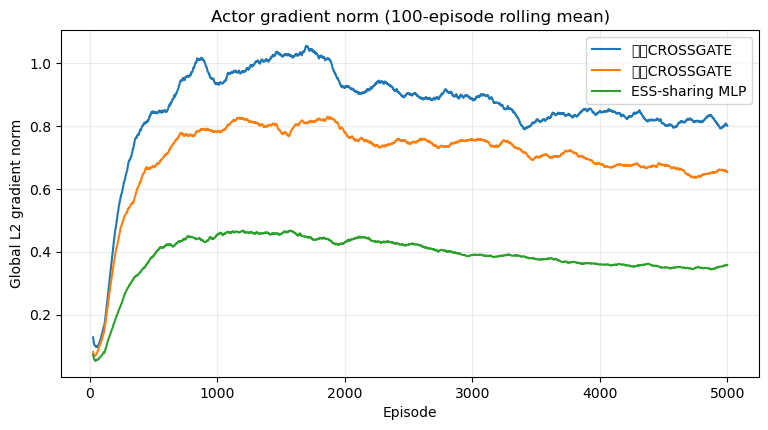

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, frame in HISTORIES.items():
    ax.plot(
        frame["episode"],
        pd.to_numeric(frame["actor_grad_norm"], errors="coerce").rolling(100, min_periods=20).mean(),
        label=name,
    )
ax.set(title="Actor gradient norm (100-episode rolling mean)", xlabel="Episode", ylabel="Global L2 gradient norm")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 3. Adjust for parameter count and configured learning rate

In [6]:
actor_parameters = {"新版CROSSGATE": 22498, "旧版CROSSGATE": 23906, "ESS-sharing MLP": 23042}
actor_lr = {"新版CROSSGATE": 2e-4, "旧版CROSSGATE": 3e-4, "ESS-sharing MLP": 3e-4}
scale_rows = []
for name, frame in HISTORIES.items():
    final = pd.to_numeric(frame.loc[frame["episode"] > 4500, "actor_grad_norm"], errors="coerce").dropna()
    mean_grad = final.mean()
    scale_rows.append({
        "method": name,
        "final500_grad_norm": mean_grad,
        "parameters": actor_parameters[name],
        "grad_norm_per_sqrt_parameter": mean_grad / math.sqrt(actor_parameters[name]),
        "learning_rate": actor_lr[name],
        "lr_times_grad_norm": actor_lr[name] * mean_grad,
    })
scale_table = pd.DataFrame(scale_rows)
scale_table

,method,final500_grad_norm,parameters,grad_norm_per_sqrt_parameter,learning_rate,lr_times_grad_norm
0,新版CROSSGATE,0.811278,22498,0.005409,0.0002,0.000162
1,旧版CROSSGATE,0.651147,23906,0.004211,0.0003,0.000195
2,ESS-sharing MLP,0.350563,23042,0.002309,0.0003,0.000105


### 4. Check whether high gradients coincide with Critic instability or validation collapse

In [7]:
stability_rows = []
for name, frame in HISTORIES.items():
    tail = frame.loc[frame["episode"] > 4500]
    validation = VALIDATION[name]
    best = validation.loc[validation["team_profit_mean"].idxmax()]
    last = validation.iloc[-1]
    stability_rows.append({
        "method": name,
        "actor_grad_final500": pd.to_numeric(tail["actor_grad_norm"], errors="coerce").mean(),
        "critic_grad_final500": pd.to_numeric(tail["critic_grad_norm"], errors="coerce").mean(),
        "critic_loss_final500": pd.to_numeric(tail["critic_loss"], errors="coerce").mean(),
        "td_error_std_final500": pd.to_numeric(tail["td_error_std"], errors="coerce").mean(),
        "q1_q2_gap_final500": pd.to_numeric(tail["q1_q2_gap"], errors="coerce").mean(),
        "best_validation_episode": int(best["episode"]),
        "best_validation_profit": best["team_profit_mean"],
        "last_validation_profit": last["team_profit_mean"],
        "validation_drop_from_best": last["team_profit_mean"] - best["team_profit_mean"],
    })
stability = pd.DataFrame(stability_rows)
stability.round(4)

,method,actor_grad_final500,critic_grad_final500,critic_loss_final500,td_error_std_final500,q1_q2_gap_final500,best_validation_episode,best_validation_profit,last_validation_profit,validation_drop_from_best
0,新版CROSSGATE,0.8113,24.1045,1.9718,0.9635,0.0500,800,-827.4560,-851.7553,-24.2993
1,旧版CROSSGATE,0.6511,24.0867,2.0082,0.9719,0.0505,1600,-864.0651,-874.3524,-10.2874
2,ESS-sharing MLP,0.3506,24.1378,1.9434,0.9563,0.0490,4900,-848.6175,-857.3370,-8.7195


### 5. Decompose best-checkpoint gradients by microgrid, action dimension, and Actor branch

In [8]:
def module_gradient_norm(*modules):
    squared = 0.0
    for module in modules:
        for parameter in module.parameters():
            if parameter.grad is not None:
                squared += float(parameter.grad.detach().norm(2).item()) ** 2
    return squared ** 0.5


def checkpoint_gradient_diagnostic(slug, run_path):
    spec = get_algorithm_spec(slug)
    base = yaml.safe_load((ROOT / "configs/cooperative.yaml").read_text(encoding="utf-8"))
    base["_project_root"] = str(ROOT)
    env = MultiMicrogridEnv(spec.build_environment_config(base), split="test")
    algorithm_config = yaml.safe_load(spec.default_config_path.read_text(encoding="utf-8"))
    algorithm = spec.create(env, algorithm_config, seed=42)
    algorithm.load(run_path / "checkpoints/best_model.pt")

    observation_rows = {mg: [] for mg in env.agent_ids}
    state_rows = []
    days = [str(day.date()) for day in env.data.valid_days][:55]
    for day_index, day in enumerate(days):
        observations, reset_info = env.reset(day=day, seed=42 + day_index, deterministic=True)
        state = reset_info["global_state"]
        done = False
        while not done:
            state_rows.append(state)
            for mg in env.agent_ids:
                observation_rows[mg].append(observations[mg])
            actions = algorithm.select_actions(observations, noise_std=0.0)
            observations, _, done, info = env.step(actions)
            state = info["global_state_after"]

    states = torch.as_tensor(np.asarray(state_rows), dtype=torch.float32, device=algorithm.device)
    observations = {
        mg: torch.as_tensor(np.asarray(rows), dtype=torch.float32, device=algorithm.device)
        for mg, rows in observation_rows.items()
    }
    batch_size = len(states)
    rows = []
    for active in env.agent_ids:
        algorithm.actors.zero_grad(set_to_none=True)
        for parameter in algorithm.critics[active].parameters():
            parameter.requires_grad_(False)
        parts = []
        active_action = None
        for mg in env.agent_ids:
            action = algorithm.actors[mg](observations[mg])
            if mg == active:
                active_action = action
                active_action.retain_grad()
                parts.append(action)
            else:
                parts.append(action.detach())
        loss = -algorithm.critics[active].q1(states, torch.cat(parts, dim=-1)).mean()
        loss.backward()
        assert active_action is not None and active_action.grad is not None
        per_sample_action_gradient = active_action.grad.detach() * batch_size
        row = {
            "microgrid": active,
            "total_parameter_grad_norm": algorithm._gradient_norm(algorithm.actors[active]),
            "battery_action_gradient_rms": float(per_sample_action_gradient[:, 0].square().mean().sqrt()),
            "offer_action_gradient_rms": float(per_sample_action_gradient[:, 1].square().mean().sqrt()),
        }
        actor = algorithm.actors[active]
        if hasattr(actor, "battery_local_encoder"):
            row["battery_branch_grad_norm"] = module_gradient_norm(
                actor.battery_local_encoder, actor.battery_backbone, actor.battery_head,
            )
            row["offer_branch_grad_norm"] = module_gradient_norm(
                actor.offer_local_encoder, actor.market_encoder, actor.peer_encoder,
                actor.local_gate, actor.peer_gate, actor.offer_backbone, actor.offer_head,
            )
        rows.append(row)
        for parameter in algorithm.critics[active].parameters():
            parameter.requires_grad_(True)
    return pd.DataFrame(rows)


new_checkpoint_gradients = checkpoint_gradient_diagnostic("crossgate_actor", RUNS["新版CROSSGATE"])
mlp_checkpoint_gradients = checkpoint_gradient_diagnostic("matd3_ess_sharing", RUNS["ESS-sharing MLP"])
new_checkpoint_gradients.round(6)

,microgrid,total_parameter_grad_norm,battery_action_gradient_rms,offer_action_gradient_rms,battery_branch_grad_norm,offer_branch_grad_norm
0,mg1,0.807594,0.409965,0.367812,0.644708,0.486375
1,mg2,0.723555,0.419204,0.376960,0.585543,0.425054
2,mg3,0.968735,0.355816,0.450778,0.322299,0.913549


In [9]:
mlp_checkpoint_gradients.round(6)

,microgrid,total_parameter_grad_norm,battery_action_gradient_rms,offer_action_gradient_rms
0,mg1,0.146553,0.279173,0.280423
1,mg2,0.342725,0.314531,0.250422
2,mg3,0.286120,0.361865,0.220034


### 6. Check deterministic test action saturation

In [10]:
hourly = pd.concat(
    [pd.read_csv(path) for path in sorted((RUNS["新版CROSSGATE"] / "test_hourly_trajectories").glob("*.csv"))],
    ignore_index=True,
)
saturation_rows = []
for mg in ("mg1", "mg2", "mg3"):
    saturation_rows.append({
        "microgrid": mg,
        "battery_action_abs_ge_0.95": (hourly[f"{mg}_raw_action_0"].abs() >= 0.95).mean(),
        "offer_action_abs_ge_0.95": (hourly[f"{mg}_raw_action_1"].abs() >= 0.95).mean(),
    })
saturation = pd.DataFrame(saturation_rows)
saturation

,microgrid,battery_action_abs_ge_0.95,offer_action_abs_ge_0.95
0,mg1,0.000000,0.138636
1,mg2,0.090909,0.072727
2,mg3,0.486364,0.131818


## Takeaways

1. **不是梯度爆炸。** 新版全程没有非有限梯度，最大回合均值约1.29；梯度在1001–2000回合达到高位，随后下降，未呈持续发散。
2. **确实存在结构性偏高。** 新版最后500回合梯度约为MLP的2.31倍；按参数数量粗略归一后仍明显更高。较低的学习率抵消了一部分风险，但Adam的真实更新量不能仅用“学习率×梯度范数”精确替代。
3. **Critic不是主要问题。** Critic梯度、损失、TD误差和Q1/Q2差距与对照方法接近，没有同步恶化。
4. **存在后期过训练信号。** 新版第800回合达到最优验证收益，至第5000回合下降约24.30；正式测试中最终检查点也弱于最优检查点。
5. **当前日志不足以追溯训练期的具体微网。** 训练更新产生了分微网梯度，但训练管线只保存总体均值。检查点分解补充了定位证据，但不能完全替代Replay Buffer上的训练期记录。